# 과제 4 — MovieLens 1M 스트리밍 알고리즘 비교
공식 데이터만 사용. 원본 파일 순서의 순차 재생이며 실시간/시간순 스트림이라고 주장하지 않는다.
결과 수치는 실행 후 생성된다. Python CPU, matplotlib 필요.

In [14]:
from pathlib import Path
from collections import Counter
from array import array
import csv, gc, hashlib, json, math, os, platform, random, statistics, struct
import subprocess, sys, time, tracemalloc, zipfile

URL = 'https://files.grouplens.org/datasets/movielens/ml-1m.zip'
RAW = Path('ml-1m/ratings.dat')
OUT = Path('results_movielens')
SEEDS = (42, 123, 2026)
NEG_COUNT = 200_000
POS_COUNT = 100_000
EXPECTED = 1_000_209
MASK = (1 << 64) - 1
PRIME = (1 << 61) - 1
assert array('I').itemsize == 4

## 1. 공식 데이터 다운로드 및 형식 검증
기존 파일이 있으면 재사용한다. 다운로드 실패 시 명확히 중단하며 업로드 대기 없음.

In [15]:
def ensure_data():
    if RAW.is_file():
        print('기존 데이터 재사용:', RAW, flush=True)
        return
    temp = Path('ml-1m.zip.part')
    try:
        subprocess.run(['curl','-fL','--connect-timeout','10','--max-time','90',URL,'-o',str(temp)], check=True)
        with zipfile.ZipFile(temp) as z:
            z.extract('ml-1m/ratings.dat')
    finally:
        temp.unlink(missing_ok=True)
    print('다운로드 및 압축 해제 완료', flush=True)

def events(path):
    with Path(path).open(encoding='ascii') as f:
        for lineno, line in enumerate(f,1):
            try:
                u,i,r,t = map(int,line.rstrip('\r\n').split('::'))
                if not (u>0 and i>0 and 1<=r<=5 and t>0 and u<2**32 and i<2**32):
                    raise ValueError('범위 오류')
            except ValueError as exc:
                raise ValueError(f'잘못된 레코드 {lineno}: {exc}') from exc
            yield u,i,r,t

def sha256(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda:f.read(1<<20),b''): h.update(b)
    return h.hexdigest()

## 2. 자료구조 직접 구현 및 단위 테스트
Bloom: bytearray, 64비트 혼합 함수 2개 + double hashing. CMS: 행별 독립 시드의 선형 모듈러 해시, uint32 카운터.

In [16]:
def mix64(x):
    x &= MASK
    x = ((x ^ (x >> 30)) * 0xbf58476d1ce4e5b9) & MASK
    x = ((x ^ (x >> 27)) * 0x94d049bb133111eb) & MASK
    return x ^ (x >> 31)

class BloomFilter:
    def __init__(self,m,k,seed=42):
        self.m=int(m); self.k=int(k)
        assert self.m>0 and self.k>0
        rng=random.Random(seed)
        self.s1=rng.getrandbits(64); self.s2=rng.getrandbits(64)
        self.bits=bytearray((self.m+7)//8)
    def hashes(self,key):
        u,i=key; x=(u<<32)|i
        return mix64(x ^ self.s1), mix64(x ^ self.s2) | 1
    def add(self,key):
        h,g=self.hashes(key); a=h%self.m; step=g%self.m
        for _ in range(self.k):
            self.bits[a>>3] |= 1<<(a&7)
            a=(a+step)%self.m
    def query(self,key):
        h,g=self.hashes(key); a=h%self.m; step=g%self.m
        for _ in range(self.k):
            if not (self.bits[a>>3] & (1<<(a&7))): return False
            a=(a+step)%self.m
        return True
    def fill(self): return sum(x.bit_count() for x in self.bits)/self.m
    def payload(self): return len(self.bits)

class CountMinSketch:
    def __init__(self,w,d,seed=42):
        self.w=int(w); self.d=int(d)
        assert self.w>0 and self.d>0
        rng=random.Random(seed)
        self.params=[(rng.randrange(1,PRIME),rng.randrange(PRIME)) for _ in range(d)]
        self.table=array('I',[0])*(w*d)
    def add(self,key):
        w=self.w
        for row,(a,b) in enumerate(self.params):
            j=row*w+((a*key+b)%PRIME)%w
            self.table[j]+=1
    def query(self,key):
        w=self.w
        return min(self.table[row*w+((a*key+b)%PRIME)%w] for row,(a,b) in enumerate(self.params))
    def payload(self): return len(self.table)*self.table.itemsize

class ExactSet:
    def __init__(self): self.data=set()
    def add(self,k): self.data.add(k)
    def query(self,k): return k in self.data

class ExactDict:
    def __init__(self): self.data={}
    def add(self,k): self.data[k]=self.data.get(k,0)+1
    def query(self,k): return self.data.get(k,0)

def unit_tests():
    keys=[(1,2),(2,3),(1,2),(10,30)]
    b=BloomFilter(128,4); c=CountMinSketch(4,3); s=ExactSet(); d=ExactDict()
    for u,i in keys: b.add((u,i)); s.add((u,i)); c.add(i); d.add(i)
    assert all(b.query(x) for x in s.data)
    assert all(c.query(i)>=v for i,v in d.data.items())
    assert c.payload()==48 and b.payload()==16
    assert s.query((1,2)) and not s.query((2,1)) and d.query(2)==2
    print('기본 자료구조 단위 테스트 통과')

## 3. Ground Truth 및 평가 질의 구성
원본 레코드를 리스트/DataFrame에 적재하지 않는다. 평가용 정답 Set/Dict는 별도로 유지하며 스케치 메모리에 포함하지 않는다.

In [17]:
def deep_size(obj):
    seen=set(); stack=[obj]; total=0
    while stack:
        x=stack.pop(); oid=id(x)
        if oid in seen: continue
        seen.add(oid); total+=sys.getsizeof(x)
        if isinstance(x,dict):
            for k,v in x.items(): stack.append(k); stack.append(v)
        elif isinstance(x,(set,list,tuple)): stack.extend(x)
        elif hasattr(x,'__dict__'): stack.append(vars(x))
    return total

def inspect(path,expected=EXPECTED):
    pairs=set(); counts={}; users=set(); ratings=Counter(); N=0; prev=None; decreases=0; lo=None; hi=None
    for u,i,r,t in events(path):
        N+=1; pairs.add((u,i)); counts[i]=counts.get(i,0)+1; users.add(u); ratings[r]+=1
        if prev is not None and t<prev: decreases+=1
        prev=t; lo=t if lo is None else min(lo,t); hi=t if hi is None else max(hi,t)
    if expected is not None and N!=expected: raise ValueError(f'공식 레코드 수 불일치: {N}')
    f=list(counts.values()); D=len(f); n=len(pairs)
    info={'records':N,'users':len(users),'movies':D,'unique_pairs':n,'pair_duplicates':N-n,
          'frequency_mean':statistics.mean(f),'frequency_median':statistics.median(f),'frequency_max':max(f),
          'freq_1':sum(v==1 for v in f),'freq_le_5':sum(v<=5 for v in f),'freq_ge_50':sum(v>=50 for v in f),
          'freq_ge_100':sum(v>=100 for v in f),'rating_distribution':dict(ratings),'timestamp_min':lo,
          'timestamp_max':hi,'timestamp_decrease_ratio':decreases/max(N-1,1),'size_bytes':Path(path).stat().st_size,
          'sha256':sha256(path), 'source':URL,'python':sys.version,'platform':platform.platform(),
          'cpu_count':os.cpu_count(),'max_movie_id':max(counts),'dense_exact_payload_reference':4*(max(counts)+1),
          'packed_key_count_reference':D*8,'dict_deep_estimate':deep_size(counts),'set_deep_estimate':deep_size(pairs)}
    return info,pairs,counts,users

def make_queries(pairs,counts,users,negative_count=NEG_COUNT,positive_count=POS_COUNT):
    rng=random.Random(2026); uu=sorted(users); ii=sorted(counts)
    available=len(uu)*len(ii)-len(pairs)
    target=min(negative_count,available)
    if target<=0: raise ValueError('음성 질의 공간 없음')
    neg=set()
    # 공식 데이터는 가능한 조합 중 실제 조합 비중이 낮아 거부 샘플링 가능.
    while len(neg)<target:
        key=(rng.choice(uu),rng.choice(ii))
        if key not in pairs: neg.add(key)
    # 실제 존재하는 키에서 균일 표본. 평가에만 메모리 사용.
    indices=set(rng.sample(range(len(pairs)),min(positive_count,len(pairs))))
    pos=[key for j,key in enumerate(pairs) if j in indices]
    return pos,sorted(neg)

def save_json(name,obj):
    OUT.mkdir(parents=True,exist_ok=True)
    (OUT/name).write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')

def save_csv(name,rows):
    if not rows: return
    OUT.mkdir(parents=True,exist_ok=True)
    with (OUT/name).open('w',encoding='utf-8-sig',newline='') as f:
        w=csv.DictWriter(f,fieldnames=list(dict.fromkeys(k for r in rows for k in r)))
        w.writeheader(); w.writerows(rows)

## 4. 실험 방법과 파라미터
업데이트 시간: 동일 원본 읽기+파싱+갱신, 메모리 추적 OFF. 조회는 별도 측정. 대표 설정 5회, 나머지 3회; 추가 시드는 정확도 평가에만 사용.

In [18]:
def stream_update(state,kind,path):
    add=state.add
    if kind=='bf':
        for u,i,r,t in events(path): add((u,i))
    else:
        for u,i,r,t in events(path): add(i)

def timing_stats(times,N):
    t=statistics.median(times)
    q=statistics.quantiles(times,n=4,method='inclusive') if len(times)>1 else [t,t,t]
    return {'update_seconds':t,'time_iqr_seconds':q[2]-q[0],'throughput_records_s':N/t,
            'timing_repeats':len(times),'all_update_seconds':json.dumps(times)}

def timed_build(factory,kind,path,N,repeats):
    times=[]
    for j in range(repeats):
        gc.collect(); state=factory(); t=time.perf_counter(); stream_update(state,kind,path)
        times.append(time.perf_counter()-t)
        if j+1<repeats: del state
    return state,timing_stats(times,N)

def traced_build(factory,kind,path):
    gc.collect(); tracemalloc.start()
    try:
        s=factory(); stream_update(s,kind,path)
        current,peak=tracemalloc.get_traced_memory()
    finally: tracemalloc.stop()
    del s
    return {'traced_retained_bytes':current,'traced_peak_bytes':peak,
            'scope':'separate build, includes Python allocations/temporary parsing; excludes existing ground truth'}

def wilson(k,n):
    p=k/n; z=1.95996398454; den=1+z*z/n
    mid=(p+z*z/(2*n))/den; half=z*math.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return max(0,mid-half),min(1,mid+half)

def bf_accuracy(state,pos,neg,n):
    t=time.perf_counter(); fn=sum(not state.query(x) for x in pos); fp=sum(state.query(x) for x in neg)
    elapsed=time.perf_counter()-t; low,high=wilson(fp,len(neg)); f=state.fill()
    assert fn==0,'false negative detected'
    return {'fp':fp,'fn':fn,'negative_queries':len(neg),'positive_queries':len(pos),'fpr':fp/len(neg),
            'fpr_ci_low':low,'fpr_ci_high':high,'theory_fpr':(-math.expm1(-state.k*n/state.m))**state.k,
            'fill_ratio':f,'fill_power_k':f**state.k,'query_seconds':elapsed,
            'query_throughput_s':(len(pos)+len(neg))/elapsed}

def cms_accuracy(state,truth,N):
    t=time.perf_counter(); estimate={i:state.query(i) for i in truth}; elapsed=time.perf_counter()-t
    errors={i:estimate[i]-v for i,v in truth.items()}; assert min(errors.values())>=0
    actual_top=sorted(truth,key=lambda i:(-truth[i],i)); estimated_top=sorted(estimate,key=lambda i:(-estimate[i],i))
    def top(k):
        k=min(k,len(truth)); return len(set(actual_top[:k])&set(estimated_top[:k]))/k
    eps=math.e/state.w; delta=math.exp(-state.d)
    row={'mae':statistics.mean(errors.values()),'max_error':max(errors.values()),
         'exact_fraction':sum(e==0 for e in errors.values())/len(truth),
         'mean_relative_error':statistics.mean(errors[i]/truth[i] for i in truth),
         'top10_precision':top(10),'top100_precision':top(100),'epsilon':eps,'delta':delta,
         'bound_satisfied_fraction':sum(e<=eps*N for e in errors.values())/len(truth),
         'single_row_expected_collision_approx':(N-N/len(truth))/state.w,
         'query_seconds':elapsed,'query_throughput_s':len(truth)/elapsed}
    bands=[]
    for label,lo,hi in [('1-5',1,5),('6-49',6,49),('50-99',50,99),('100+',100,float('inf'))]:
        ids=[i for i,v in truth.items() if lo<=v<=hi]
        bands.append({'frequency_band':label,'items':len(ids),'mae':statistics.mean(errors[i] for i in ids) if ids else None,
                      'mean_relative_error':statistics.mean(errors[i]/truth[i] for i in ids) if ids else None})
    row['high_freq_mean_relative_error']=bands[-1]['mean_relative_error']
    return row,bands

def configs(n,D,dict_bytes):
    # m 고정/ k 고정 비교를 분리, 목표 1% 설정 추가. m은 바이트 배수.
    def bits(b): return math.ceil(n*b/8)*8
    bf={(bits(b),6) for b in (2,4,6,8,10,12,16)}
    bf.update((bits(8),k) for k in (1,3,6,9,12))
    bf.update((bits(12),k) for k in (3,8,12))
    bf.add((bits(9.6),7)); bf_ref=(bits(9.6),7)
    widths={max(1,round(D/x)) for x in (100,30,10,3,1)}|{2*D}
    # Python dict 추정치에 대한 payload crossing: 아래/근처/위. 보조 메모리 기준은 결과에 표시.
    widths.update(max(1,math.ceil(dict_bytes*ratio/20)) for ratio in (.5,1,2))
    cms={(w,5) for w in widths}
    cms.update((max(1,round(D/10)),d) for d in (1,3,5,8))
    same_budgets=[]
    for W in (max(2,2*round(D/20)),max(2,2*round(D/2))):
        combos=[(4*W,1),(2*W,2),(W,4),(W//2,8)]
        cms.update(combos); same_budgets.append(16*W)
    cms_ref=(2719,5); cms.add(cms_ref)
    return sorted(bf),sorted(cms),bf_ref,cms_ref,same_budgets

## 5. 본 실험 실행
모든 결과는 매 설정마다 CSV에 저장. Colab 연결이 끊기지 않도록 진행 상황을 표시한다.

In [19]:
def run_experiments(path,info,pairs,truth,users,quick=False):
    N=info['records']; n=len(pairs); D=len(truth)
    if N!=n: raise ValueError('이 용량 실험은 고유 조합 100%인 MovieLens 1M 전용입니다.')
    pos,neg=make_queries(pairs,truth,users,negative_count=2000 if quick else NEG_COUNT,positive_count=1000 if quick else POS_COUNT)
    bcfg,ccfg,bref,cref,budgets=configs(n,D,info['dict_deep_estimate'])
    plan={'bloom_configs':bcfg,'cms_configs':ccfg,'bloom_reference':bref,'cms_reference':cref,
          'cms_equal_memory_payload_budgets':budgets,'seeds':SEEDS,'positive_queries':len(pos),'negative_queries':len(neg),
          'quick_test_only':quick,'timing_policy':'representative 5 repeats, other 3 repeats, same seed 42; other seeds accuracy only',
          'bloom_fpr_target':.01,'cms_high_frequency_relative_error_target':.05,'cms_top100_precision_target':.95}
    save_json('experiment_plan.json',plan)
    if quick: bcfg=[bref,bcfg[0]]; ccfg=[cref,ccfg[0]]
    reps=lambda ref: 1 if quick else (5 if ref else 3)
    # 짧은 준비 실행은 전체 데이터 1회 파싱, 측정에서 제외.
    print('파일 파싱 준비 및 반복 측정 시작',flush=True)
    for _ in events(path): pass
    parse_times=[]
    for _ in range(reps(True)):
        t=time.perf_counter()
        for _ in events(path): pass
        parse_times.append(time.perf_counter()-t)
    baseline=[]; trace=[]
    for name,fac,kind in [('Set',ExactSet,'bf'),('Dictionary',ExactDict,'cms')]:
        print(f'기준 구조 측정 시작: {name}',flush=True)
        s,ts=timed_build(fac,kind,path,N,reps(True)); memory=deep_size(s)
        t=time.perf_counter()
        if kind=='bf':
            assert all(s.query(x) for x in pos) and not any(s.query(x) for x in neg); qn=len(pos)+len(neg)
        else:
            assert all(s.query(i)==v for i,v in truth.items()); qn=D
        qt=time.perf_counter()-t
        baseline.append({'algorithm':name,'deep_bytes':memory,'query_seconds':qt,'query_throughput_s':qn/qt,**ts})
        del s
        if not quick: trace.append({'algorithm':name,**traced_build(fac,kind,path)})
    save_csv('baseline.csv',baseline); save_csv('traced_memory.csv',trace)
    bfrows=[]; cmsrows=[]; bandrows=[]
    for j,(m,k) in enumerate(bcfg,1):
        print(f'Bloom {j}/{len(bcfg)} 시작: m={m:,}, k={k}',flush=True)
        reference=(m,k)==bref; fac=lambda m=m,k=k: BloomFilter(m,k,SEEDS[0])
        s,ts=timed_build(fac,'bf',path,N,reps(reference)); memory=deep_size(s)
        vals=bf_accuracy(s,pos,neg,n); row={'m':m,'k':k,'bits_per_key':m/n,'seed':SEEDS[0],
            'reference':reference,'payload_bytes':s.payload(),'deep_bytes':memory,**ts,**vals}
        bfrows.append(row); del s
        if reference and not quick: trace.append({'algorithm':'Bloom Filter',**traced_build(fac,'bf',path)})
        # 대표와 k 극단 설정에만 시드 반복
        if not quick and (reference or (k in (1,12) and abs(m/n-8)<.01)):
            for seed in SEEDS[1:]:
                s=BloomFilter(m,k,seed); stream_update(s,'bf',path)
                bfrows.append({'m':m,'k':k,'bits_per_key':m/n,'seed':seed,'reference':reference,
                               'payload_bytes':s.payload(),'deep_bytes':deep_size(s),**bf_accuracy(s,pos,neg,n)})
                del s
        save_csv('bloom.csv',bfrows); save_csv('traced_memory.csv',trace)
        print(f'Bloom {j}/{len(bcfg)} m/n={m/n:.2f}, k={k}, FPR={vals["fpr"]:.5f}',flush=True)
    for j,(w,d) in enumerate(ccfg,1):
        print(f'CMS {j}/{len(ccfg)} 시작: w={w:,}, d={d}',flush=True)
        reference=(w,d)==cref; fac=lambda w=w,d=d: CountMinSketch(w,d,SEEDS[0])
        s,ts=timed_build(fac,'cms',path,N,reps(reference)); memory=deep_size(s)
        for si,seed in enumerate(SEEDS[:1] if quick else SEEDS):
            if si:
                s=CountMinSketch(w,d,seed); stream_update(s,'cms',path)
            vals,bands=cms_accuracy(s,truth,N)
            row={'w':w,'d':d,'seed':seed,'reference':reference,'payload_bytes':s.payload(),'deep_bytes':deep_size(s),
                 'equal_memory_group':s.payload() if s.payload() in budgets else None,**(ts if si==0 else {}),**vals}
            cmsrows.append(row); bandrows.extend(dict(w=w,d=d,seed=seed,**b) for b in bands)
            del s
        if reference and not quick: trace.append({'algorithm':'Count-Min Sketch',**traced_build(fac,'cms',path)})
        save_csv('cms.csv',cmsrows); save_csv('cms_frequency_bands.csv',bandrows); save_csv('traced_memory.csv',trace)
        print(f'CMS {j}/{len(ccfg)} width={w}, depth={d}',flush=True)
    # 포화 실험: 원본에 중복이 없으므로 이벤트 개수 = 실제 삽입 고유 키 수.
    print('Bloom 용량 초과 실험 시작',flush=True)
    n0=math.ceil(n/2); m=math.ceil(n0*9.6/8)*8; b=BloomFilter(m,7,SEEDS[0])
    checkpoints=sorted(set(min(n,max(1,round(n0*q))) for q in (.25,.5,1,1.5,2)))
    sat=[]
    for j,(u,i,r,t) in enumerate(events(path),1):
        b.add((u,i))
        if j in checkpoints:
            fp=sum(b.query(x) for x in neg); lo,hi=wilson(fp,len(neg))
            sat.append({'inserted_unique':j,'design_n':n0,'load_ratio':j/n0,'m':m,'k':7,'fpr':fp/len(neg),
                        'fpr_ci_low':lo,'fpr_ci_high':hi,'theory_fpr':(-math.expm1(-7*j/m))**7,'fill_ratio':b.fill()})
    save_csv('bloom_saturation.csv',sat)
    save_json('parse_timing.json',timing_stats(parse_times,N))
    parse_median=statistics.median(parse_times)
    parse_iqr=timing_stats(parse_times,N)['time_iqr_seconds']
    for name,rows in [('baseline.csv',baseline),('bloom.csv',bfrows),('cms.csv',cmsrows)]:
        for row in rows:
            if 'update_seconds' in row:
                diff=row['update_seconds']-parse_median
                resolution=max(parse_iqr,row['time_iqr_seconds'])
                row['net_update_seconds_estimate']=diff if diff>resolution else None
                row['net_time_note']='difference of medians; not direct timing' if diff>resolution else 'below measurement variability'
        save_csv(name,rows)
    return baseline,bfrows,cmsrows,bandrows,sat,plan

## 6. 그래프와 결과 요약
seed 42는 시간 비교; CMS 정확도는 설정별 3개 시드 평균. 실용성 기준은 과제용 가정, 산업 표준이 아니다.

In [20]:
def summarize_results(info,baseline,bf,cms,bands,sat,plan):
    base={r['algorithm']:r for r in baseline}; b0=[r for r in bf if r['seed']==SEEDS[0]]
    c0=[r for r in cms if r['seed']==SEEDS[0]]; group={}
    for r in cms: group.setdefault((r['w'],r['d']),[]).append(r)
    cmean=[]
    for r in c0:
        rr=group[(r['w'],r['d'])]; entry=dict(r)
        for k in ('mae','mean_relative_error','high_freq_mean_relative_error','top100_precision','top10_precision','exact_fraction'):
            vals=[x[k] for x in rr if x[k] is not None]
            entry[k+'_seed_mean']=statistics.mean(vals) if vals else None
            entry[k+'_seed_sd']=statistics.stdev(vals) if len(vals)>1 else None
        entry['dict_memory_ratio']=r['deep_bytes']/base['Dictionary']['deep_bytes']
        cmean.append(entry)
    for r in b0: r['set_memory_ratio']=r['deep_bytes']/base['Set']['deep_bytes']
    save_csv('bloom_summary.csv',b0); save_csv('cms_summary.csv',cmean)
    goodb=[r for r in b0 if r['fpr']<=.01]
    goodc=[r for r in cmean if r['high_freq_mean_relative_error_seed_mean'] is not None and r['high_freq_mean_relative_error_seed_mean']<=.05 and r['top100_precision_seed_mean']>=.95]
    out={'bloom_min_memory_meeting_target':min(goodb,key=lambda r:r['deep_bytes']) if goodb else None,
         'cms_min_memory_meeting_targets':min(goodc,key=lambda r:r['deep_bytes']) if goodc else None,
         'cms_configs_larger_than_dict':sum(r['dict_memory_ratio']>1 for r in cmean),
         'dict_deep_bytes':base['Dictionary']['deep_bytes'],'set_deep_bytes':base['Set']['deep_bytes'],
         'dense_exact_counter_payload_reference':info['dense_exact_payload_reference'],
         'note':'dense exact reference = uint32 per movie ID including gaps; not measured or a third implemented algorithm. Top-K is offline over known movie IDs; ties broken by movie ID ascending.'}
    save_json('decision_summary.json',out)
    return b0,cmean,out

def figures(info,base,bf,cms,bands,sat,plan):
    import matplotlib.pyplot as plt
    def finish(name):
        plt.tight_layout(); plt.savefig(OUT/name,dpi=160); plt.show(); plt.close()
    plt.figure(figsize=(7,4))
    a=sorted([r for r in bf if r['k']==6],key=lambda r:r['m']); plt.plot([r['bits_per_key'] for r in a],[r['fpr'] for r in a],'o-',label='Measured'); plt.plot([r['bits_per_key'] for r in a],[r['theory_fpr'] for r in a],'--',label='Theory'); plt.xlabel('Bits per distinct pair (k=6)'); plt.ylabel('False positive rate'); plt.legend(); finish('01_bloom_bits.png')
    plt.figure(figsize=(7,4))
    for b in (8,12):
        a=sorted([r for r in bf if abs(r['bits_per_key']-b)<.01],key=lambda r:r['k']); plt.plot([r['k'] for r in a],[r['fpr'] for r in a],'o-',label=f'{b} bits/key')
    plt.xlabel('Hash count k'); plt.ylabel('False positive rate'); plt.legend(); finish('02_bloom_k.png')
    plt.figure(figsize=(7,4)); plt.plot([r['load_ratio'] for r in sat],[r['fpr'] for r in sat],'o-',label='Measured'); plt.plot([r['load_ratio'] for r in sat],[r['theory_fpr'] for r in sat],'--',label='Theory'); plt.axvline(1,linestyle=':',label='Design capacity'); plt.xlabel('Distinct inserted / design capacity'); plt.ylabel('False positive rate'); plt.legend(); finish('03_bloom_saturation.png')
    plt.figure(figsize=(7,4)); a=sorted([r for r in cms if r['d']==5],key=lambda r:r['w']); plt.plot([r['payload_bytes']/1024 for r in a],[r['mae_seed_mean'] for r in a],'o-'); plt.xscale('log'); plt.axvline(next(r['deep_bytes'] for r in base if r['algorithm']=='Dictionary')/1024,linestyle='--',label='Dict deep bytes (reference)'); plt.xlabel('CMS payload (KiB), d=5'); plt.ylabel('Mean absolute error'); plt.legend(); finish('04_cms_memory_error.png')
    plt.figure(figsize=(7,4)); a=sorted([r for r in cms if r['d']==5],key=lambda r:r['w']); x=[r['w'] for r in a]
    for label in ('1-5','6-49','50-99','100+'):
        y=[]
        for w in x:
            v=[r['mean_relative_error'] for r in bands if r['w']==w and r['d']==5 and r['frequency_band']==label and r['mean_relative_error'] is not None]; y.append(statistics.mean(v) if v else float('nan'))
        plt.plot(x,y,'o-',label=label)
    plt.xscale('log'); plt.yscale('symlog',linthresh=.001); plt.xlabel('Width, d=5'); plt.ylabel('Mean relative error'); plt.legend(title='True frequency'); finish('05_cms_frequency.png')
    plt.figure(figsize=(7,4))
    for budget in plan['cms_equal_memory_payload_budgets']:
        a=sorted([r for r in cms if r['payload_bytes']==budget],key=lambda r:r['d']); plt.plot([r['d'] for r in a],[r['mae_seed_mean'] for r in a],'o-',label=f'{budget/1024:.1f} KiB')
    plt.xlabel('Depth (same counter payload)'); plt.ylabel('Mean absolute error'); plt.legend(); finish('06_cms_equal_memory.png')
    bb=next(r for r in bf if r['reference']); cc=next(r for r in cms if r['reference']); names=['Set','Bloom','Dict','CMS']; rows=[base[0],bb,base[1],cc]
    plt.figure(figsize=(7,4)); plt.bar(names,[r['deep_bytes']/1024 for r in rows]); plt.yscale('log'); plt.ylabel('Estimated retained object size (KiB)'); finish('07_reference_memory.png')
    plt.figure(figsize=(7,4)); plt.bar(names,[r['throughput_records_s'] for r in rows]); plt.ylabel('End-to-end update throughput (records/s)'); finish('08_reference_throughput.png')

def package_results():
    dest=Path('movielens_results.zip')
    with zipfile.ZipFile(dest,'w',zipfile.ZIP_DEFLATED) as z:
        for p in sorted(OUT.iterdir()):
            if p.is_file(): z.write(p,arcname=f'{OUT.name}/{p.name}')
    print('결과 ZIP:',dest.resolve(),flush=True)
    return dest

## 7. STEP A — 공식 다운로드 / 기본 테스트
CPU 런타임 권장. 기존 탐색 노트북과 동일 세션이면 이미 받은 파일을 재사용합니다. 다운로드 실패 시 중단되며 파일 업로드 대화상자를 띄우지 않습니다.

In [21]:
unit_tests()
ensure_data()
print(RAW.resolve())

기본 자료구조 단위 테스트 통과
기존 데이터 재사용: ml-1m/ratings.dat
/content/ml-1m/ratings.dat


## 8. STEP B — 실제 데이터 검증
정답 Set/Dict를 구성하고 입력 레코드 수, 고유 키 수, 빈도 분포 및 메모리 설계값을 출력합니다.

In [22]:
info,pairs,truth,users=inspect(RAW)
save_json("dataset.json",info)
print(json.dumps(info,ensure_ascii=False,indent=2))
assert info["records"]==1_000_209
assert info["unique_pairs"]==1_000_209

{
  "records": 1000209,
  "users": 6040,
  "movies": 3706,
  "unique_pairs": 1000209,
  "pair_duplicates": 0,
  "frequency_mean": 269.88909875876953,
  "frequency_median": 123.5,
  "frequency_max": 3428,
  "freq_1": 114,
  "freq_le_5": 329,
  "freq_ge_50": 2514,
  "freq_ge_100": 2019,
  "rating_distribution": {
    "5": 226310,
    "3": 261197,
    "4": 348971,
    "2": 107557,
    "1": 56174
  },
  "timestamp_min": 956703932,
  "timestamp_max": 1046454590,
  "timestamp_decrease_ratio": 0.48800549485706973,
  "size_bytes": 24594131,
  "sha256": "506d64ca44484487c11dc2d9a28de5c54948213e6b96285e298afe28d6ea4e0f",
  "source": "https://files.grouplens.org/datasets/movielens/ml-1m.zip",
  "python": "3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "cpu_count": 2,
  "max_movie_id": 3952,
  "dense_exact_payload_reference": 15812,
  "packed_key_count_reference": 29648,
  "dict_deep_estimate": 284996,
  "set_deep_estimate": 142653540
}

## 9. STEP C — 본 실험 계획 확인
대표 파라미터 5회, 나머지 3회 반복하며 CMS는 추가 시드로 정확도를 검증합니다. 각 설정마다 실제 파일 전체를 다시 읽습니다. 본 실험은 다운로드보다 훨씬 오래 걸릴 수 있습니다.

In [23]:
bcfg,ccfg,bref,cref,budgets=configs(info["unique_pairs"],info["movies"],info["dict_deep_estimate"])
print("Bloom 설정 수:",len(bcfg),bcfg)
print("CMS 설정 수:",len(ccfg),ccfg)
print("대표 설정:",bref,cref)
print("동일 메모리 카운터 예산(bytes):",budgets)

Bloom 설정 수: 15 [(2000424, 6), (4000840, 6), (6001256, 6), (8001672, 1), (8001672, 3), (8001672, 6), (8001672, 9), (8001672, 12), (9602008, 7), (10002096, 6), (12002512, 3), (12002512, 6), (12002512, 8), (12002512, 12), (16003344, 6)]
CMS 설정 수: 21 [(37, 5), (124, 5), (185, 8), (370, 4), (371, 1), (371, 3), (371, 5), (371, 8), (740, 2), (1235, 5), (1480, 1), (1853, 8), (2719, 5), (3706, 4), (3706, 5), (7125, 5), (7412, 2), (7412, 5), (14250, 5), (14824, 1), (28500, 5)]
대표 설정: (9602008, 7) (2719, 5)
동일 메모리 카운터 예산(bytes): [5920, 59296]


## 10. STEP D — 본 실험 실행
설정 시작/완료를 화면에 출력하며 각 설정 완료 시 CSV를 저장합니다. 실험 비교의 공정성을 위해 다른 셀과 동시에 실행하지 마세요. 결과가 아직 없는데 그래프나 결론을 작성하지 않습니다.

In [24]:
base,bf,cms,bands,sat,plan=run_experiments(RAW,info,pairs,truth,users)

파일 파싱 준비 및 반복 측정 시작
기준 구조 측정 시작: Set
기준 구조 측정 시작: Dictionary
Bloom 1/15 시작: m=2,000,424, k=6
Bloom 1/15 m/n=2.00, k=6, FPR=0.73536
Bloom 2/15 시작: m=4,000,840, k=6
Bloom 2/15 m/n=4.00, k=6, FPR=0.21891
Bloom 3/15 시작: m=6,001,256, k=6
Bloom 3/15 m/n=6.00, k=6, FPR=0.06340
Bloom 4/15 시작: m=8,001,672, k=1
Bloom 4/15 m/n=8.00, k=1, FPR=0.11589
Bloom 5/15 시작: m=8,001,672, k=3
Bloom 5/15 m/n=8.00, k=3, FPR=0.03025
Bloom 6/15 시작: m=8,001,672, k=6
Bloom 6/15 m/n=8.00, k=6, FPR=0.02152
Bloom 7/15 시작: m=8,001,672, k=9
Bloom 7/15 m/n=8.00, k=9, FPR=0.02959
Bloom 8/15 시작: m=8,001,672, k=12
Bloom 8/15 m/n=8.00, k=12, FPR=0.04753
Bloom 9/15 시작: m=9,602,008, k=7
Bloom 9/15 m/n=9.60, k=7, FPR=0.00997
Bloom 10/15 시작: m=10,002,096, k=6
Bloom 10/15 m/n=10.00, k=6, FPR=0.00851
Bloom 11/15 시작: m=12,002,512, k=3
Bloom 11/15 m/n=12.00, k=3, FPR=0.01056
Bloom 12/15 시작: m=12,002,512, k=6
Bloom 12/15 m/n=12.00, k=6, FPR=0.00364
Bloom 13/15 시작: m=12,002,512, k=8
Bloom 13/15 m/n=12.00, k=8, FPR=0.00313
Bloom 14/15

## 11. STEP E — 실제 측정 결과 요약 및 그래프
아래 결과가 최종 보고서의 근거입니다. 실용성 기준은 실험용 가정이며 산업 표준이 아닙니다. 정확한 구조의 메모리가 작을 수 있는 정수 ID 특성도 해석에 포함합니다.

{
  "bloom_min_memory_meeting_target": {
    "m": 9602008,
    "k": 7,
    "bits_per_key": 9.60000159966567,
    "seed": 42,
    "reference": true,
    "payload_bytes": 1200251,
    "deep_bytes": 1200811,
    "update_seconds": 5.394341733999681,
    "time_iqr_seconds": 1.2954455680001047,
    "throughput_records_s": 185418.17506589193,
    "timing_repeats": 5,
    "all_update_seconds": "[5.299256550999871, 6.734217986000203, 5.258500475999881, 6.594702118999976, 5.394341733999681]",
    "fp": 1994,
    "fn": 0,
    "negative_queries": 200000,
    "positive_queries": 100000,
    "fpr": 0.00997,
    "fpr_ci_low": 0.009543897970156038,
    "fpr_ci_high": 0.010414925968946075,
    "theory_fpr": 0.009965146631545643,
    "fill_ratio": 0.517727646134017,
    "fill_power_k": 0.009970329139132785,
    "query_seconds": 0.9900550130000738,
    "query_throughput_s": 303013.46496992855,
    "net_update_seconds_estimate": 4.33040285099969,
    "net_time_note": "difference of medians; not direct tim

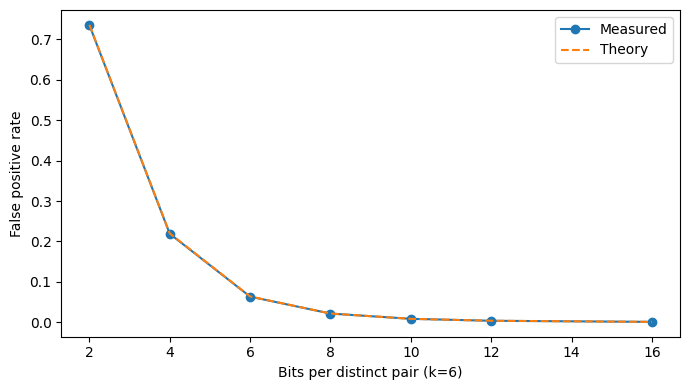

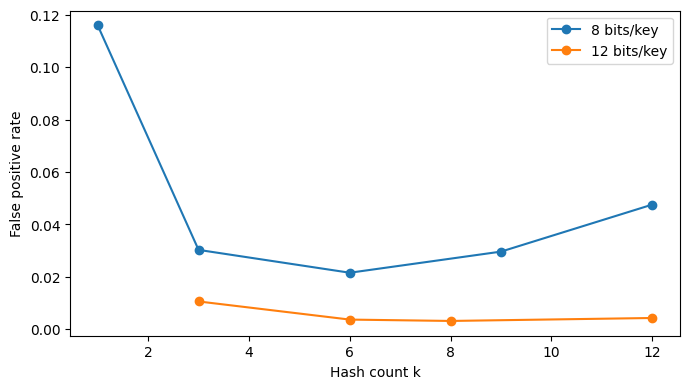

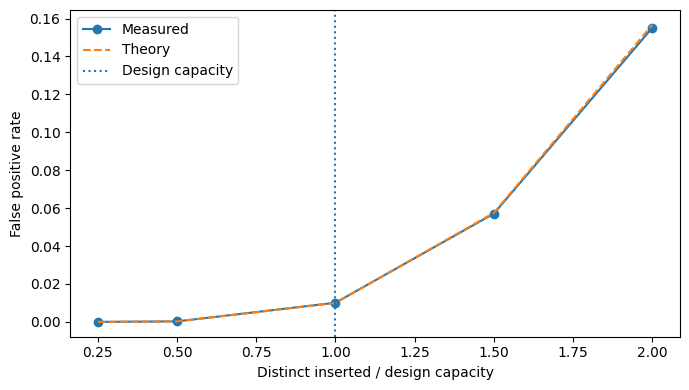

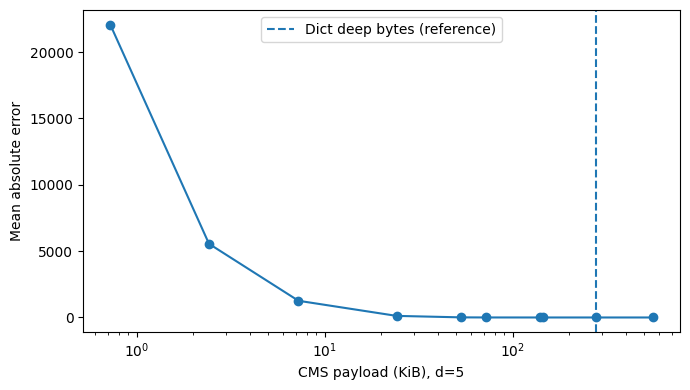

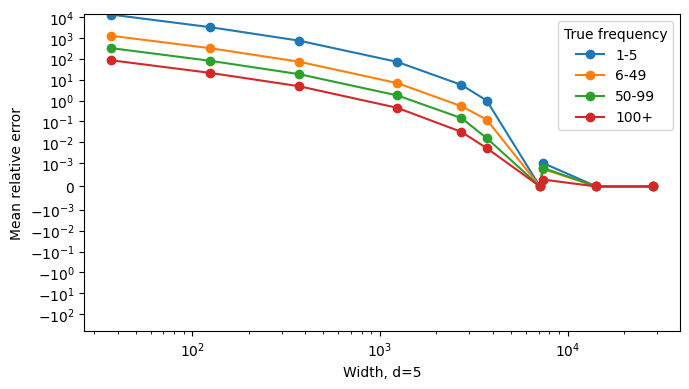

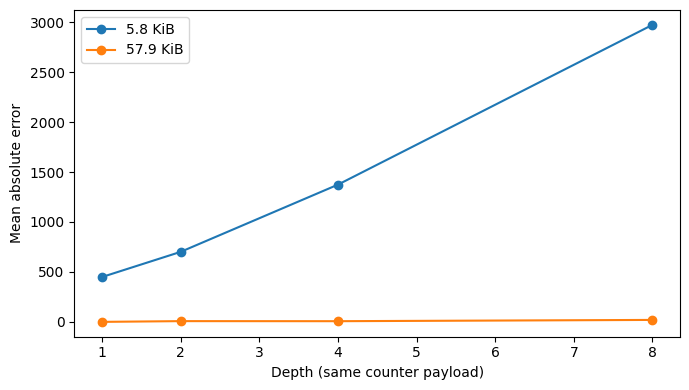

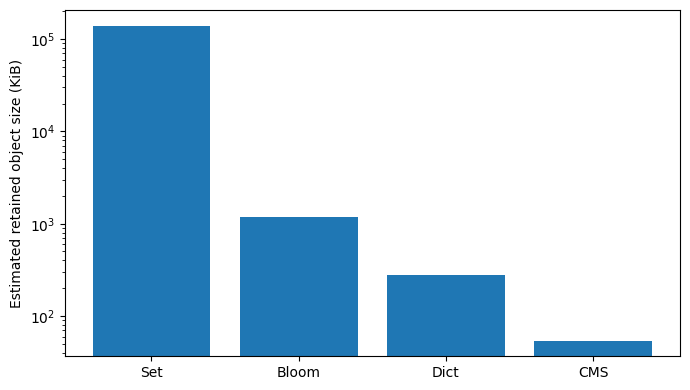

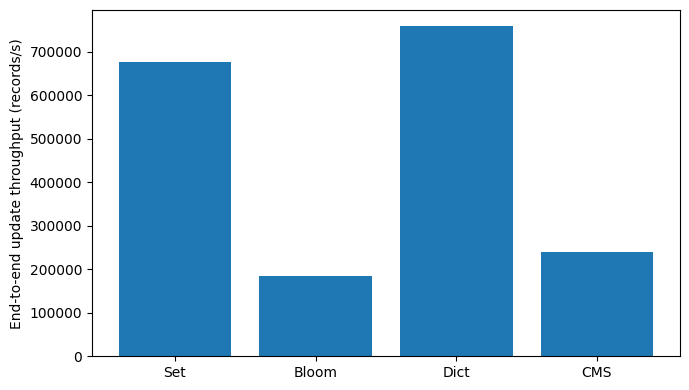

In [25]:
b0,cmean,summary=summarize_results(info,base,bf,cms,bands,sat,plan)
print(json.dumps(summary,ensure_ascii=False,indent=2))
figures(info,base,b0,cmean,bands,sat,plan)

## 12. STEP F — 결과 파일 받기
원본 MovieLens 데이터는 ZIP에 넣지 않습니다. GitHub에는 이 노트북과 소스코드, 결과 파일만 올릴 수 있습니다.

In [26]:
result_zip=package_results()
from google.colab import files
files.download(str(result_zip))

결과 ZIP: /content/movielens_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>